# Практика 7 - t-SNE, UMAP, TriMAP, PaCMAP, PHATE
Свой датасет - Wine (`my_data.csv`).

t‑SNE: нелинейное вложение, оптимизирует дивергенцию Кульбака–Лейблера между распределениями близостей точек, хорошо показывает локальные кластеры, но медленно, плохо сохраняет глобальные расстояния, чувствительно к perplexity и random_state.

UMAP: основан на теории многобразий и топологии, строит взвешенный граф соседей и оптимизирует кросс‑энтропию; быстрее t‑SNE, лучше сохраняет глобальную структуру, более устойчив к малым изменениям параметров (n_neighbors, min_dist).

TriMAP: ориентирован на сохранение глобальной структуры через тройки точек (anchor, сосед, далёкий), улучшает глобальное расположение кластеров при сохранении локальной структуры.

PaCMAP: управляет соотношением близких, средних и далёких пар, чтобы одновременно хорошо держать локальные кластеры и общую форму; показывает хорошие результаты на омикс‑данных и эмбеддингах.

PHATE: использует диффузионные процессы и потенциал для визуализации непрерывных траекторий (например, дифференцировка клеток), хорошо показывает как кластеры, так и переходы между ними.



## Установка
trimap при установке собирает annoy - около минуты.

In [1]:
%pip install -q umap-learn trimap pacmap phate scikit-learn seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_wine, make_blobs
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold, f_classif
from sklearn.metrics import pairwise_distances, adjusted_rand_score
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.manifold import TSNE, trustworthiness
from scipy.spatial import procrustes

import umap
import trimap
import pacmap
import phate

import contextlib, io, os, time, warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

## 2. Данные
### 2.1. Iris

In [3]:
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
feature_names_iris = iris.feature_names
print(X_iris.shape, np.unique(y_iris))


(150, 4) [0 1 2]


### 2.2. Собственный датасет
Wine, сохранён в `my_data.csv` (если файла нет - создаётся).

In [4]:
path = "my_data.csv"  # замените на свой путь
if not os.path.exists(path):
    load_wine(as_frame=True).frame.to_csv(path, index=False)   # 13 признаков + столбец target
df = pd.read_csv(path)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [5]:
feature_cols = [c for c in df.columns if c != "target"]
X_own = df[feature_cols].values
y_own = df["target"].values
print(X_own.shape, len(np.unique(y_own)))


(178, 13) 3


Стандартизую оба датасета.

In [6]:
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

scaler_own = StandardScaler()
X_own_scaled = scaler_own.fit_transform(X_own)
own_name = "Wine (свой датасет)"

Функции для DR и оценки разделения

In [7]:
import logging
logging.getLogger("pacmap").setLevel(logging.ERROR)  # PaCMAP пишет в лог предупреждение о random_state

def run_tsne(X, random_state=42, perplexity=30, learning_rate=200, n_iter=1000):
    tsne = TSNE(
        n_components=2,
        perplexity=min(perplexity, len(X) - 1),
        learning_rate=learning_rate,
        max_iter=n_iter,
        init="pca",
        random_state=random_state,
    )
    return tsne.fit_transform(X)

def run_umap(X, random_state=42, n_neighbors=15, min_dist=0.1):
    reducer = umap.UMAP(n_components=2, n_neighbors=n_neighbors, min_dist=min_dist,
                        random_state=random_state)
    return reducer.fit_transform(X)

def run_trimap(X, random_state=42, n_inliers=10, n_outliers=5):
    np.random.seed(random_state)
    reducer = trimap.TRIMAP(n_dims=2, n_inliers=n_inliers, n_outliers=n_outliers, verbose=False)
    return reducer.fit_transform(X)

def run_pacmap(X, random_state=42, n_neighbors=10):
    reducer = pacmap.PaCMAP(n_components=2, n_neighbors=n_neighbors, random_state=random_state)
    return reducer.fit_transform(X)

def run_phate(X, random_state=42, knn=15):
    phate_op = phate.PHATE(n_components=2, knn=knn, random_state=random_state, verbose=0)
    return phate_op.fit_transform(X)

METHODS = {"t-SNE": run_tsne, "UMAP": run_umap, "TriMAP": run_trimap,
           "PaCMAP": run_pacmap, "PHATE": run_phate}

# прогрев numba, чтобы компиляция не попала в замер времени
_warm = np.random.RandomState(0).normal(size=(80, 5))
for f in METHODS.values():
    f(_warm)
print("Методы готовы:", list(METHODS))

    SGD-MDS may not have converged: stress changed by 3.1% in final iterations. Consider increasing n_iter or adjusting learning_rate.


Методы готовы: ['t-SNE', 'UMAP', 'TriMAP', 'PaCMAP', 'PHATE']


Функция оценки качества разделения

In [8]:
def separation_score(X_2d, y):
    D = pairwise_distances(X_2d)
    same = D[y[:, None] == y[None, :]]
    diff = D[y[:, None] != y[None, :]]
    return same.mean(), diff.mean(), diff.mean() / same.mean()


ARI (KMeans во вложении) и trustworthiness:

In [9]:
def evaluate_embedding(X_high, X_2d, y, k=10):
    same, diff, ratio = separation_score(X_2d, y)
    labels = KMeans(n_clusters=len(np.unique(y)), n_init=10, random_state=0).fit_predict(X_2d)
    return {"внутрикласс.": same, "межкласс.": diff, "ratio": ratio,
            "ARI (KMeans во влож.)": adjusted_rand_score(y, labels),
            "trustworthiness": trustworthiness(X_high, X_2d, n_neighbors=k)}

def compare_methods(X, y, methods=METHODS):
    embs, rows = {}, []
    for name, f in methods.items():
        t0 = time.perf_counter()
        E = f(X)
        dt = time.perf_counter() - t0
        embs[name] = E
        rows.append({"Метод": name, "Время, с": dt, **evaluate_embedding(X, E, y)})
    return embs, pd.DataFrame(rows).set_index("Метод")

def plot_grid(embs, y, title, ncols=5, s=15):
    n = len(embs)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4 * nrows), squeeze=False)
    for ax, (name, E) in zip(axes.flat, embs.items()):
        sns.scatterplot(x=E[:, 0], y=E[:, 1], hue=y, palette="tab10", s=s, ax=ax, legend=False)
        ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()

In [10]:
# Отрисовка

def plot_embedding(X_2d, y, title):
    plt.figure(figsize=(6, 5))
    sns.scatterplot(
        x=X_2d[:, 0],
        y=X_2d[:, 1],
        hue=y,
        palette="tab10",
        s=30,
        legend="full"
    )
    plt.title(title)
    plt.xticks([])
    plt.yticks([])
    plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


## 3. Сравнение методов на Iris

    SGD-MDS may not have converged: stress changed by -1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.


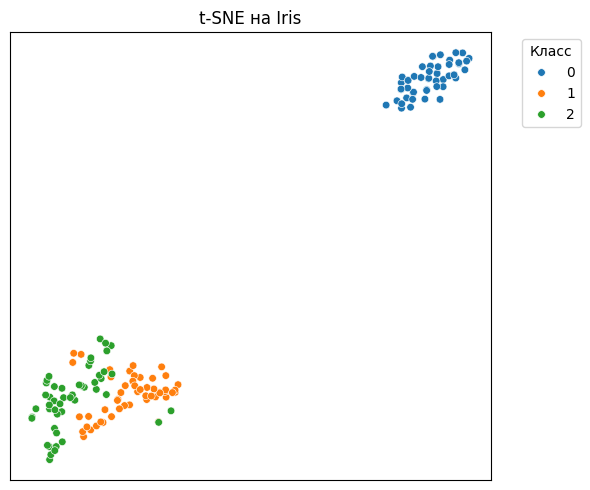

t-SNE: внутрикласс.=3.589, межкласс.=27.507, ratio=7.664


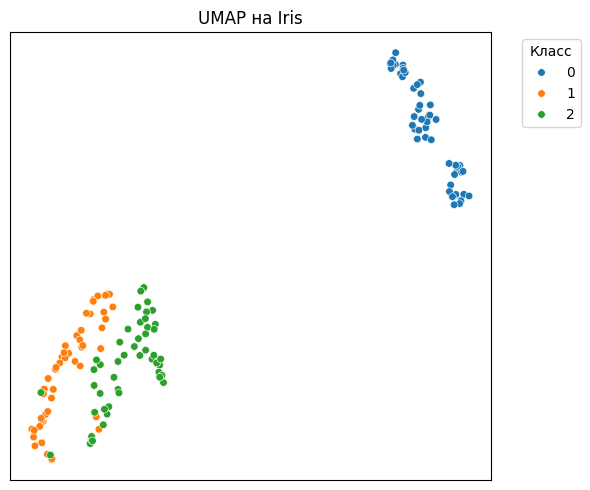

UMAP: внутрикласс.=1.873, межкласс.=13.178, ratio=7.037


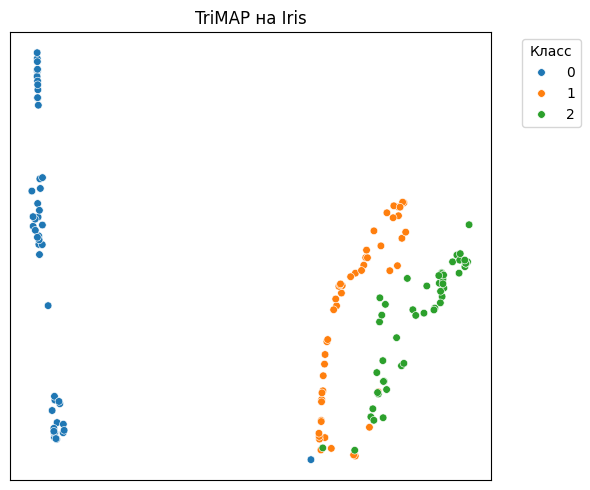

TriMAP: внутрикласс.=10.948, межкласс.=60.544, ratio=5.530


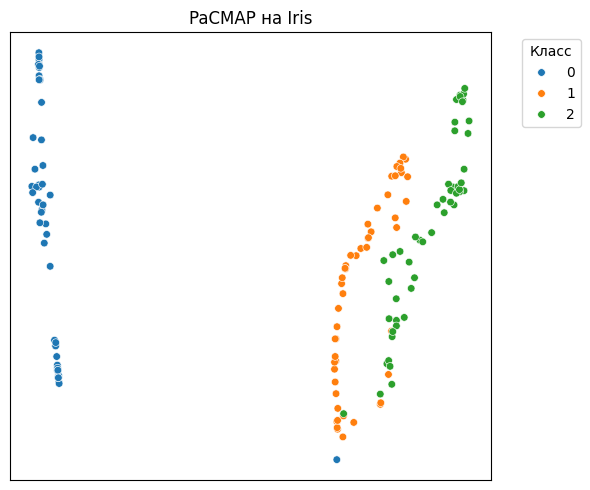

PaCMAP: внутрикласс.=3.470, межкласс.=17.673, ratio=5.093


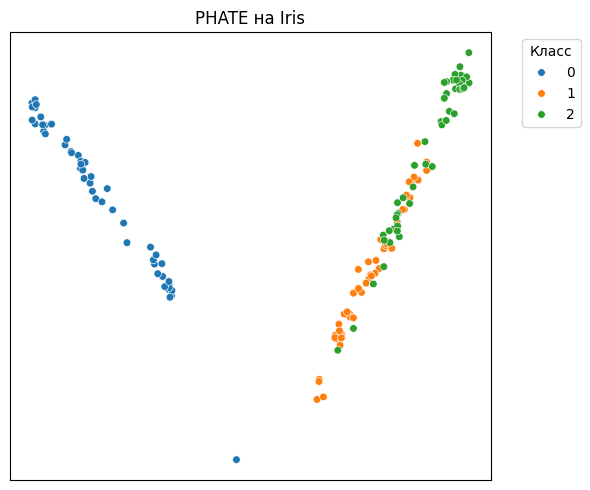

PHATE: внутрикласс.=0.026, межкласс.=0.121, ratio=4.610


In [11]:
X_list = []
names = []

X_tsne_iris = run_tsne(X_iris_scaled, random_state=42)
X_list.append(X_tsne_iris); names.append("t-SNE")

X_umap_iris = run_umap(X_iris_scaled, random_state=42)
X_list.append(X_umap_iris); names.append("UMAP")

X_trimap_iris = run_trimap(X_iris_scaled, random_state=42)
X_list.append(X_trimap_iris); names.append("TriMAP")

X_pacmap_iris = run_pacmap(X_iris_scaled, random_state=42)
X_list.append(X_pacmap_iris); names.append("PaCMAP")

X_phate_iris = run_phate(X_iris_scaled, random_state=42)
X_list.append(X_phate_iris); names.append("PHATE")

for X_emb, name in zip(X_list, names):
    plot_embedding(X_emb, y_iris, f"{name} на Iris")
    same, diff, ratio = separation_score(X_emb, y_iris)
    print(
        f"{name}: внутрикласс.={same:.3f}, межкласс.={diff:.3f}, ratio={ratio:.3f}"
    )

In [12]:
embs_iris, res_iris = compare_methods(X_iris_scaled, y_iris)
res_iris.round(3)

    SGD-MDS may not have converged: stress changed by -1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.


,"Время, с",внутрикласс.,межкласс.,ratio,ARI (KMeans во влож.),trustworthiness
Метод,,,,,,
t-SNE,0.469,3.589,27.507,7.664,0.652,0.986
UMAP,0.147,1.873,13.178,7.037,0.652,0.978
TriMAP,0.156,10.994,60.271,5.482,0.571,0.976
PaCMAP,0.236,3.470,17.673,5.093,0.562,0.974
PHATE,0.087,0.026,0.121,4.610,0.571,0.936


- ratio: t-SNE 7.7 > UMAP 7.0 > TriMAP 5.5 > PaCMAP 5.1 > PHATE 4.6.
- Локальную структуру лучше держит t-SNE (trustworthiness 0.986).
- PHATE рисует versicolor → virginica одной веткой.

## 4. Сравнение методов на собственном датасете (Wine)

    SGD-MDS may not have converged: stress changed by -5.5% in final iterations. Consider increasing n_iter or adjusting learning_rate.


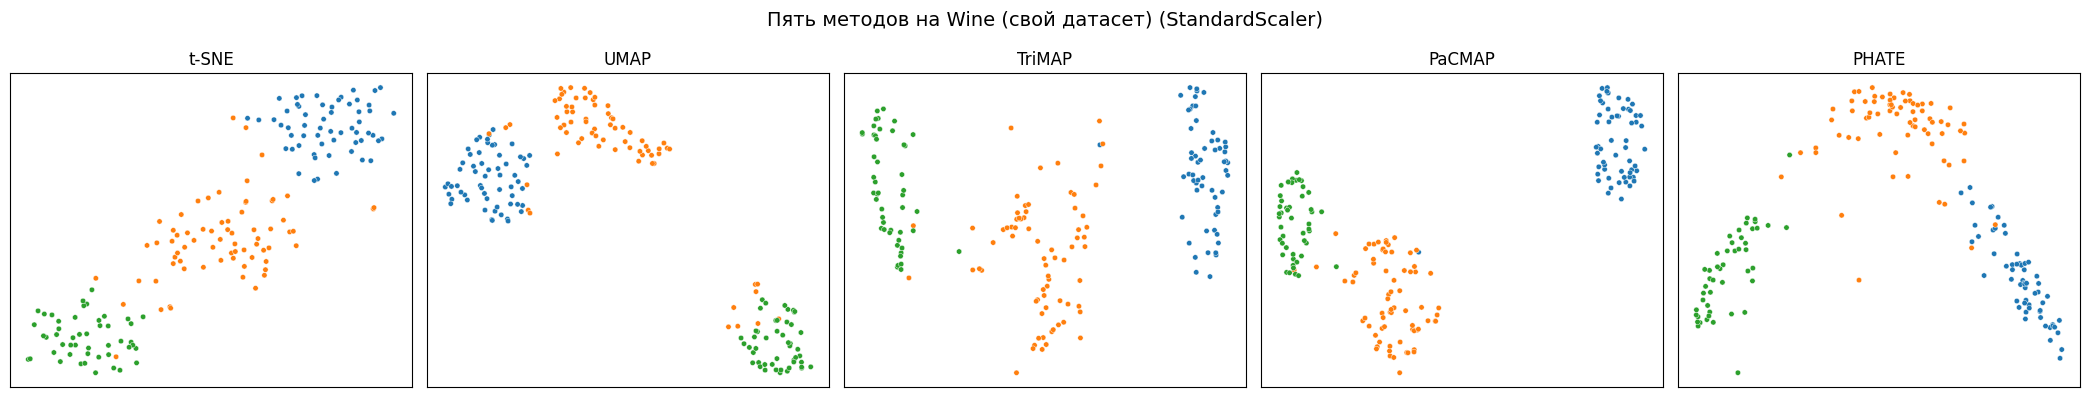

,"Время, с",внутрикласс.,межкласс.,ratio,ARI (KMeans во влож.),trustworthiness
Метод,,,,,,
t-SNE,0.538,4.533,15.186,3.350,0.788,0.962
UMAP,0.201,1.982,6.971,3.518,0.774,0.946
TriMAP,0.221,9.163,53.615,5.851,0.949,0.939
PaCMAP,0.245,2.281,15.269,6.695,0.933,0.943
PHATE,0.110,0.026,0.118,4.583,0.913,0.892


In [13]:
embs_own, res_own = compare_methods(X_own_scaled, y_own)
plot_grid(embs_own, y_own, f"Пять методов на {own_name} (StandardScaler)")
res_own.round(3)

Wine: лучше PaCMAP и TriMAP (ARI ≈ 0.93–0.95), PHATE 0.91, t-SNE/UMAP ≈ 0.78. Методы с упором на глобальную структуру лучше раскладывают сорта.

## 5. Устойчивость к гиперпараметрам

Сравнение устойчивости

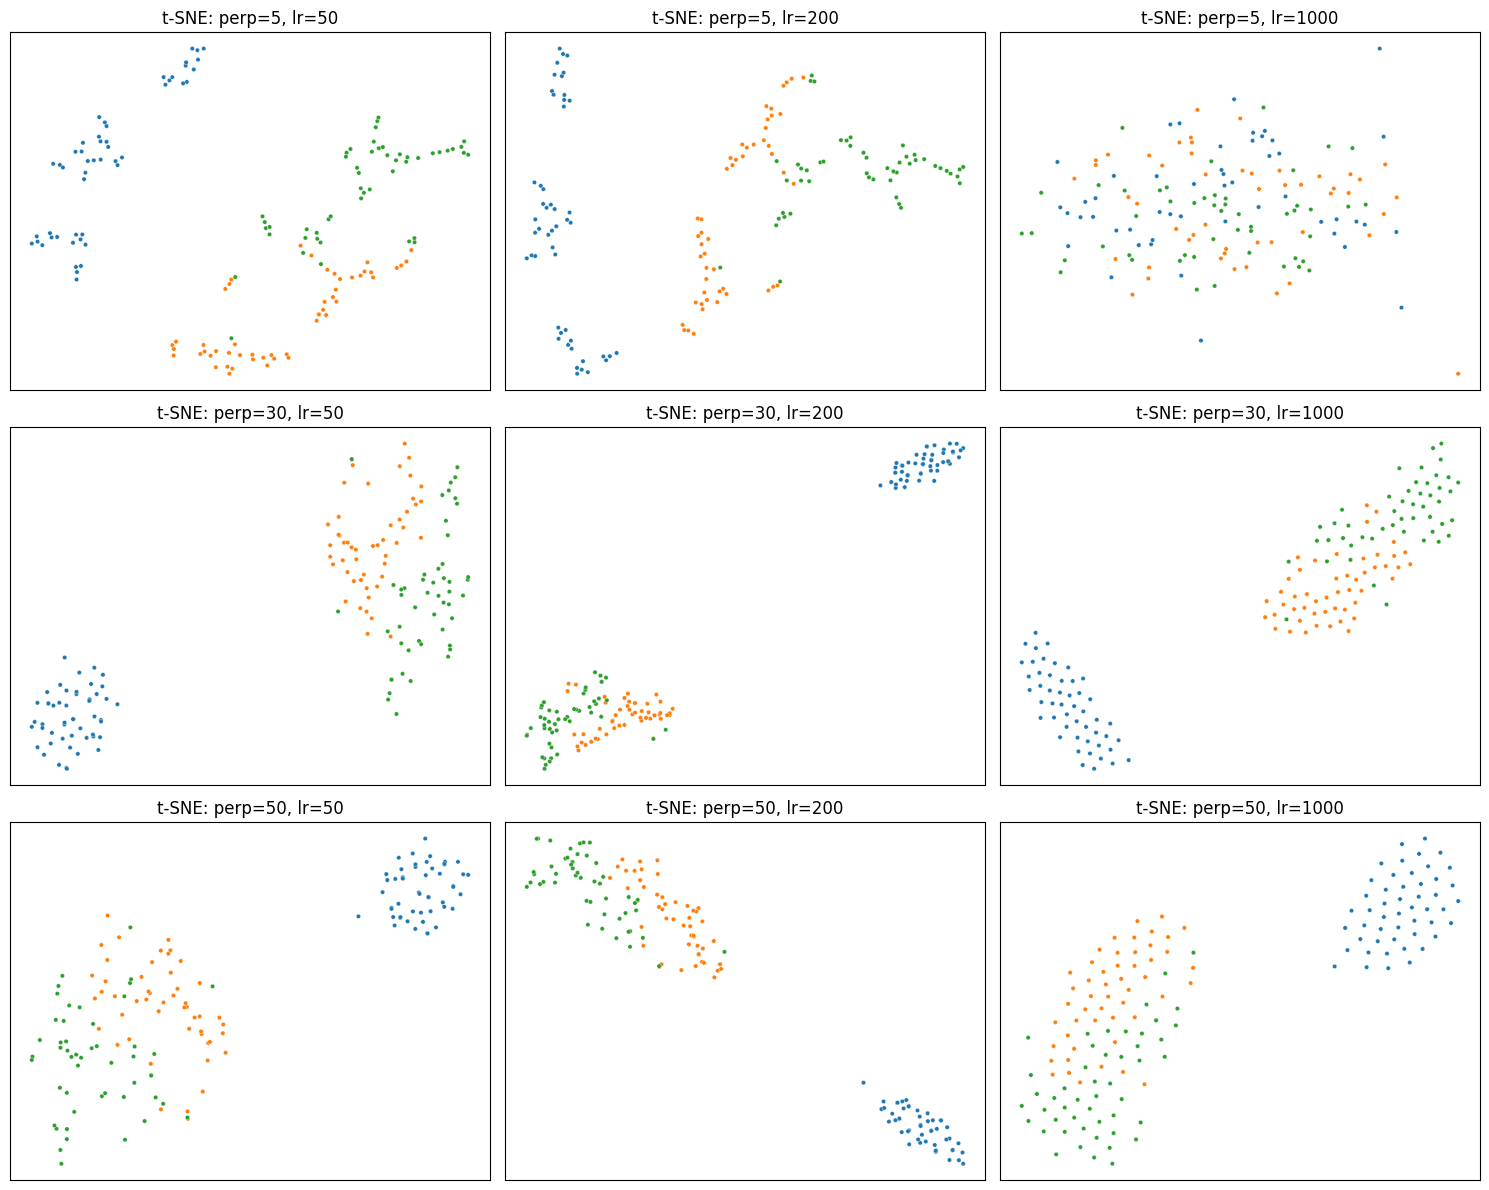

In [14]:
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        X_emb = run_tsne(X_iris_scaled, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()


Нужно описать, как меняется форма и расположение кластеров при разных perplexity и learning_rate и что визуализация t‑SNE может сильно меняться.

- perplexity 5 - ложные мини-кластеры.
- perplexity 30 и 50 - стабильно 3 группы, меняются только положение и поворот.
- lr = 1000 при perplexity 5 - оптимизация разваливается; lr = 50 - сходится медленно.

### UMAP: сетка `n_neighbors` × `min_dist`

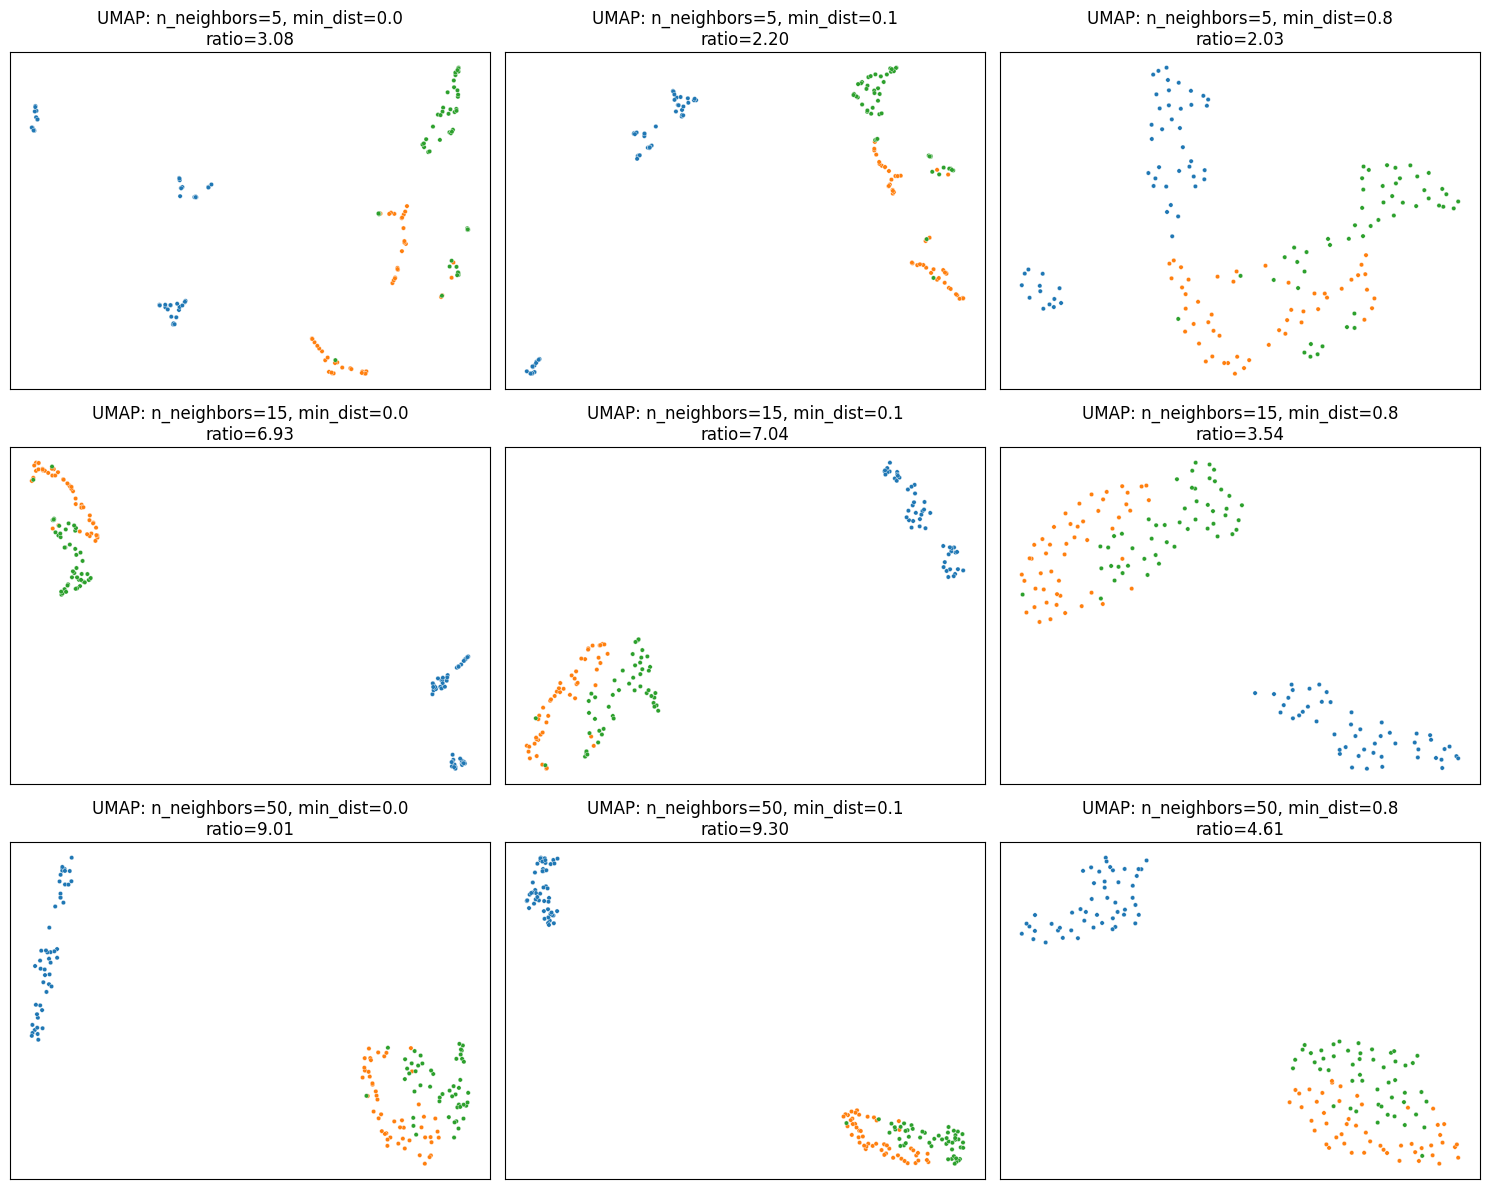

min_dist      0.0   0.1   0.8
n_neighbors                  
5            3.08  2.20  2.03
15           6.93  7.04  3.54
50           9.01  9.30  4.61


In [15]:
n_neighbors_list = [5, 15, 50]
min_dists = [0.0, 0.1, 0.8]

fig, axes = plt.subplots(len(n_neighbors_list), len(min_dists),
                         figsize=(5 * len(min_dists), 4 * len(n_neighbors_list)))
umap_grid_rows = []
for i, nn in enumerate(n_neighbors_list):
    for j, md_ in enumerate(min_dists):
        X_emb = run_umap(X_iris_scaled, random_state=42, n_neighbors=nn, min_dist=md_)
        ratio = separation_score(X_emb, y_iris)[2]
        umap_grid_rows.append({"n_neighbors": nn, "min_dist": md_, "ratio": ratio})
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"UMAP: n_neighbors={nn}, min_dist={md_}\nratio={ratio:.2f}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()
print(pd.DataFrame(umap_grid_rows).pivot(index="n_neighbors", columns="min_dist", values="ratio").round(2))

Обычно структура UMAP меняется плавнее, кластеры остаются узнаваемыми при разумном диапазоне параметров.

*Задача* Аналогично нужно сделать по одной строке графиков для TriMAP, PaCMAP, PHATE с варьированием ключевого параметра (количество соседей или похожий гиперпараметр) и показать, насколько устойчив рисунок.



Строка на метод: TriMAP - `n_inliers`, PaCMAP - `n_neighbors`, PHATE - `knn`.

    SGD-MDS may not have converged: stress changed by -1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by -1.2% in final iterations. Consider increasing n_iter or adjusting learning_rate.


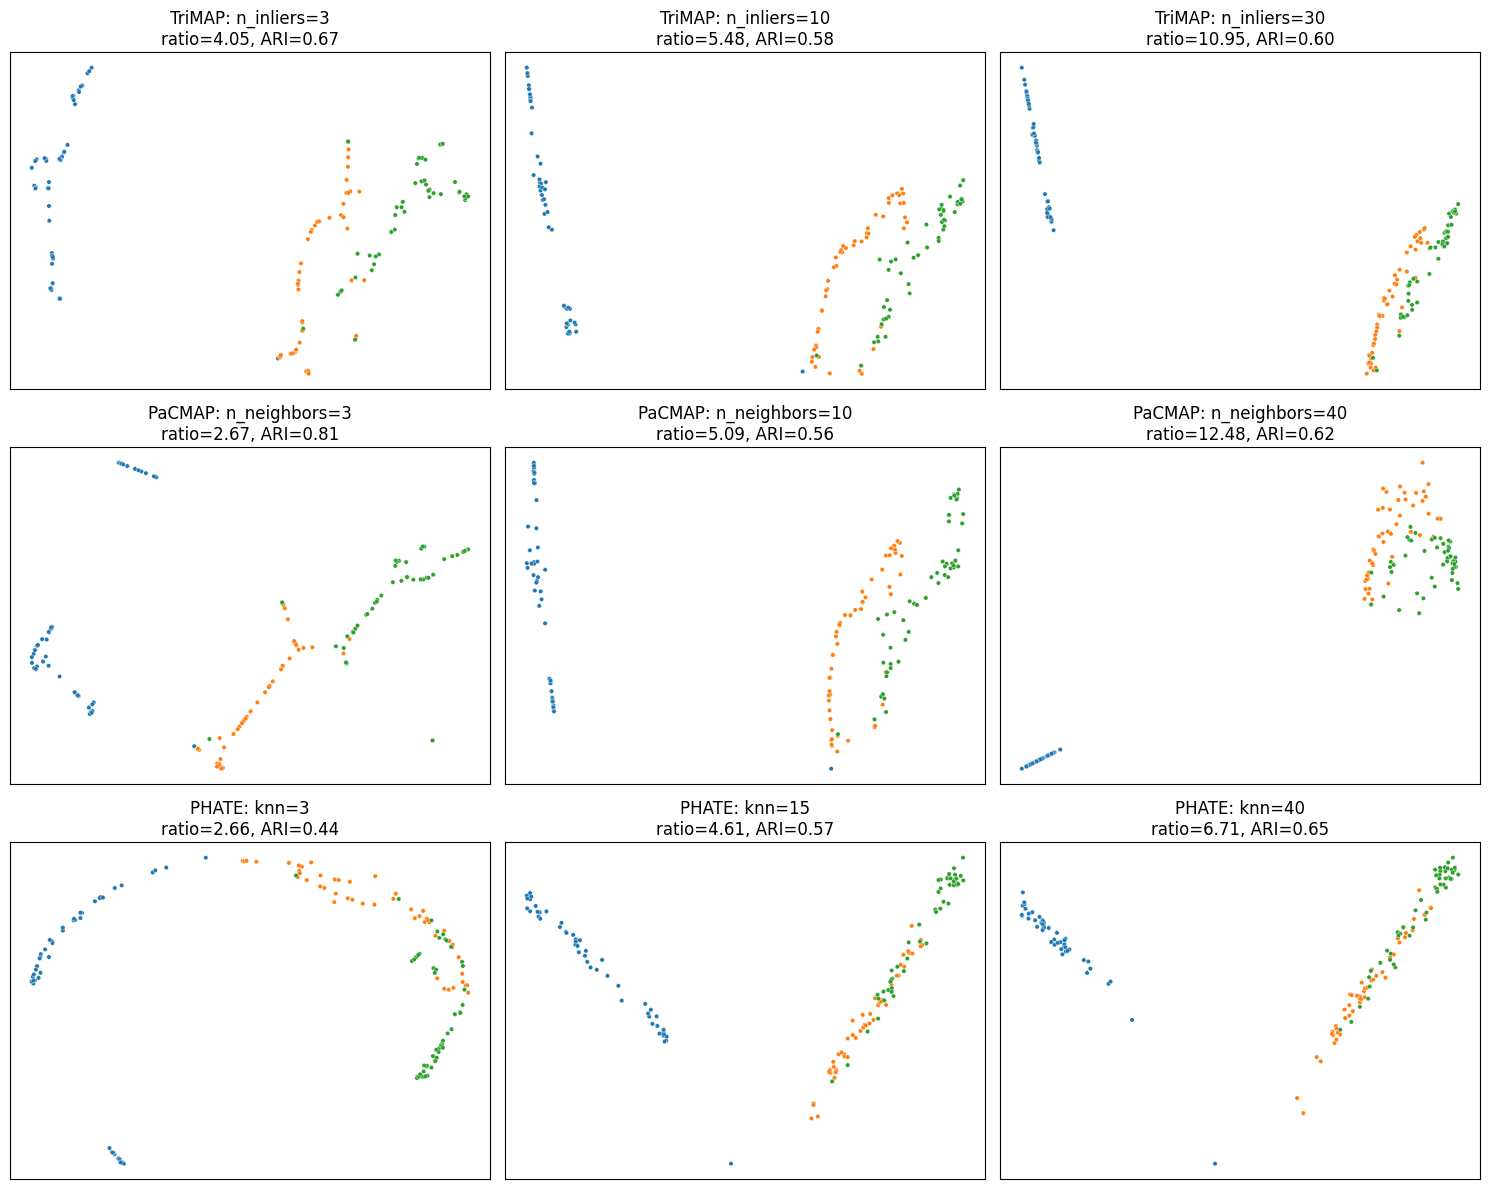

,Метод,параметр,ratio,ARI,trust.
0,TriMAP,n_inliers=3,4.048,0.668,0.973
1,TriMAP,n_inliers=10,5.480,0.580,0.975
2,TriMAP,n_inliers=30,10.947,0.601,0.967
3,PaCMAP,n_neighbors=3,2.671,0.814,0.971
4,PaCMAP,n_neighbors=10,5.093,0.562,0.974
5,PaCMAP,n_neighbors=40,12.481,0.620,0.956
6,PHATE,knn=3,2.661,0.438,0.944
7,PHATE,knn=15,4.610,0.571,0.936
8,PHATE,knn=40,6.713,0.645,0.930


In [16]:
param_grid = {
    "TriMAP": ("n_inliers", [3, 10, 30], run_trimap),
    "PaCMAP": ("n_neighbors", [3, 10, 40], run_pacmap),
    "PHATE":  ("knn", [3, 15, 40], run_phate),
}
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
param_rows = []
for i, (name, (pname, values, f)) in enumerate(param_grid.items()):
    for j, v in enumerate(values):
        X_emb = f(X_iris_scaled, random_state=42, **{pname: v})
        m = evaluate_embedding(X_iris_scaled, X_emb, y_iris)
        param_rows.append({"Метод": name, "параметр": f"{pname}={v}", "ratio": m["ratio"],
                           "ARI": m["ARI (KMeans во влож.)"], "trust.": m["trustworthiness"]})
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"{name}: {pname}={v}\nratio={m['ratio']:.2f}, ARI={m['ARI (KMeans во влож.)']:.2f}")
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
pd.DataFrame(param_rows).round(3)

Параметр меняет в основном компактность (ratio растёт с числом соседей), раскладка групп та же. PaCMAP с 3 соседями: ARI 0.81 при низком ratio - метрики могут не совпадать.

### Устойчивость к seed
5 запусков, Procrustes между вложениями.

In [17]:
seeds = [0, 1, 2, 3, 4]
stab_rows = []
for name, f in METHODS.items():
    embs_s = [f(X_iris_scaled, random_state=s) for s in seeds]
    ratios = [separation_score(E, y_iris)[2] for E in embs_s]
    aris = [evaluate_embedding(X_iris_scaled, E, y_iris)["ARI (KMeans во влож.)"] for E in embs_s]
    disp = [procrustes(embs_s[a], embs_s[b])[2] for a in range(len(seeds)) for b in range(a + 1, len(seeds))]
    stab_rows.append({"Метод": name, "ratio mean": np.mean(ratios), "ratio std": np.std(ratios),
                      "ARI mean": np.mean(aris), "ARI std": np.std(aris),
                      "Procrustes между запусками": np.mean(disp)})
stab_df = pd.DataFrame(stab_rows).set_index("Метод")
stab_df.round(3)

    SGD-MDS may not have converged: stress changed by 5.0% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by -4.9% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by 11.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by -9.7% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by 4.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.


,ratio mean,ratio std,ARI mean,ARI std,Procrustes между запусками
Метод,,,,,
t-SNE,7.664,0.000,0.652,0.000,0.000
UMAP,6.257,0.841,0.629,0.015,0.049
TriMAP,5.486,0.139,0.562,0.000,0.003
PaCMAP,5.234,0.031,0.592,0.043,0.004
PHATE,4.606,0.003,0.577,0.005,0.000


t-SNE (init='pca') и PHATE детерминированы, TriMAP и PaCMAP почти (0.003–0.004), UMAP сильнее всех зависит от seed (ratio 6.3 ± 0.8).

| Метод  | Скорость на больших данных                   | Локальное разделение              | Глобальная структура                            | Чувствительность к параметрам                         | Комментарий                                        |
| ------ | -------------------------------------------- | --------------------------------- | ----------------------------------------------- | ----------------------------------------------------- | -------------------------------------------------- |
| t‑SNE  | Низкая l                    | Отличное                   | Слабая                                   | Высокая (perplexity, lr, random_state) aicompetence+2 | Хорошо для локальных кластеров, тяжёлый тюнинг     |
| UMAP   | Высокая l                   | Очень хорошее   | Лучшая, чем у t‑SNE           | Ниже, чем у t‑SNE aicompetence+2                      | Хороший баланс локал/глобал, удобен в практике     |
| TriMAP | Средняя                              | Хорошее                   | Сильный упор на глобальную структуру    | Умеренная                                     | Лучше показывает относительное положение кластеров |
| PaCMAP | Средняя                               | Отличное                   | Хорошее                                  | Умеренная                                      | Часто даёт чёткие кластеры и форму многобразия     |
| PHATE  | Средняя/низкая (зависит от размера)   | Хорошее        | Очень хорошее, особенно для траекторий   | Умеренная                          | Сильный метод для непрерывных переходов            |

Таблица подтверждается: t-SNE лучший локально, TriMAP/PaCMAP/PHATE - глобально, t-SNE самый чувствительный к параметрам. Уточнение: UMAP с фиксированным seed работает в один поток и на больших n медленнее PaCMAP/TriMAP.

# Варианты препроцессинга
*Задача* - явно сравнить, как UMAP и t‑SNE реагируют на разные варианты нормировки и отбора признаков.

## Определяем три сценария
Без масштабирования (сырой набор признаков).

StandardScaler (z‑нормировка).

MinMaxScaler + отбор признаков по дисперсии (эмуляция feature selection).

Задание. Проделать все три сценария. Обучить все модели при разных сценария кластеризации. 
Нужно в результате:
1. описать, какие признаки были отброшены и почему это может влиять на качество кластеризации во вложенном пространстве.
1. сравнить вычислительное время и сделать вывод о масштабируемости методов
1. изменить гиперпараметры (perplexity, n_neighbors, min_dist) и исследовать совместное влияние гиперпараметров и препроцессинга на структуру кластеров.


## 6. Сценарии предобработки
Сценарий 3: MinMax + VarianceThreshold(0.04). Смотрю, что выкинулось, и F-статистику выкинутых признаков.

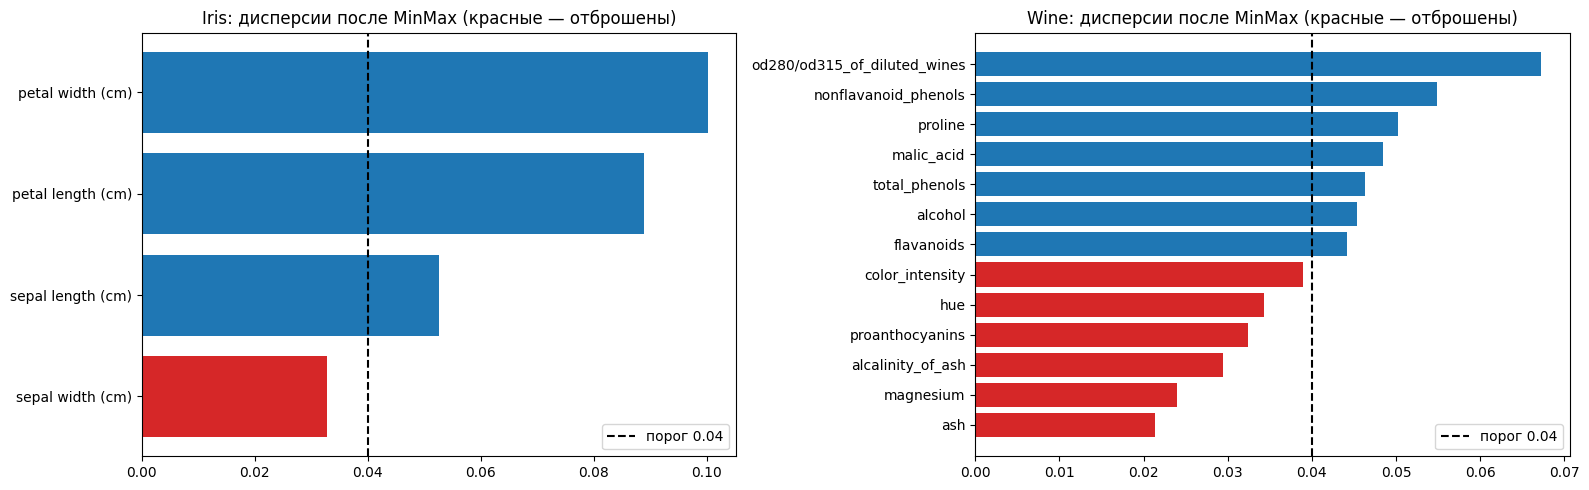


Iris: отброшено 1 из 4 признаков
                   дисперсия после MinMax  F (ANOVA)  отброшен
petal length (cm)                   0.089   1180.161     False
petal width (cm)                    0.100    960.007     False
sepal length (cm)                   0.053    119.265     False
sepal width (cm)                    0.033     49.160      True

Wine: отброшено 6 из 13 признаков
                              дисперсия после MinMax  F (ANOVA)  отброшен
flavanoids                                     0.044    233.926     False
proline                                        0.050    207.920     False
od280/od315_of_diluted_wines                   0.067    189.972     False
alcohol                                        0.045    135.078     False
color_intensity                                0.039    120.664      True
hue                                            0.034    101.317      True
total_phenols                                  0.046     93.733     False
malic_acid              

In [18]:
VAR_THRESHOLD = 0.04

def make_scenarios(X, feature_names, var_threshold=VAR_THRESHOLD):
    X_mm = MinMaxScaler().fit_transform(X)
    sel = VarianceThreshold(var_threshold).fit(X_mm)
    kept = sel.get_support()
    scen = {
        "1. Без масштабирования": X,
        "2. StandardScaler": StandardScaler().fit_transform(X),
        "3. MinMax + отбор по дисперсии": X_mm[:, kept],
    }
    return scen, np.array(feature_names)[~kept], X_mm.var(axis=0)

datasets = {
    "Iris": (X_iris, y_iris, list(feature_names_iris)),
    "Wine": (X_own, y_own, feature_cols),
}
scenarios, dropped_info = {}, {}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (ds, (X_raw, y_raw, fnames)) in zip(axes, datasets.items()):
    scen, dropped, var_mm = make_scenarios(X_raw, fnames)
    scenarios[ds] = scen
    F, _ = f_classif(X_raw, y_raw)
    info = pd.DataFrame({"дисперсия после MinMax": var_mm, "F (ANOVA)": F}, index=fnames)
    info["отброшен"] = info.index.isin(dropped)
    dropped_info[ds] = info.sort_values("дисперсия после MinMax")
    colors = ["tab:red" if d else "tab:blue" for d in dropped_info[ds]["отброшен"]]
    ax.barh(dropped_info[ds].index, dropped_info[ds]["дисперсия после MinMax"], color=colors)
    ax.axvline(VAR_THRESHOLD, color="k", linestyle="--", label=f"порог {VAR_THRESHOLD}")
    ax.set_title(f"{ds}: дисперсии после MinMax (красные — отброшены)"); ax.legend()
plt.tight_layout(); plt.show()

for ds, info in dropped_info.items():
    print(f"\n{ds}: отброшено {info['отброшен'].sum()} из {len(info)} признаков")
    print(info.round(3).sort_values("F (ANOVA)", ascending=False))

- Iris: выкинута ширина чашелистика (самая слабая, F = 49) - это полезно.
- Wine: выкинуто 6 из 13, в том числе color_intensity и hue (F ≈ 120 и 101): у них выбросы, MinMax их сжимает.
- Низкая дисперсия ≠ неинформативность.

### Все методы × сценарии × оба датасета

    SGD-MDS may not have converged: stress changed by -2.1% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by -1.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by -3.2% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by -5.1% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by -5.5% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by -6.7% in final iterations. Consider increasing n_iter or adjusting learning_rate.


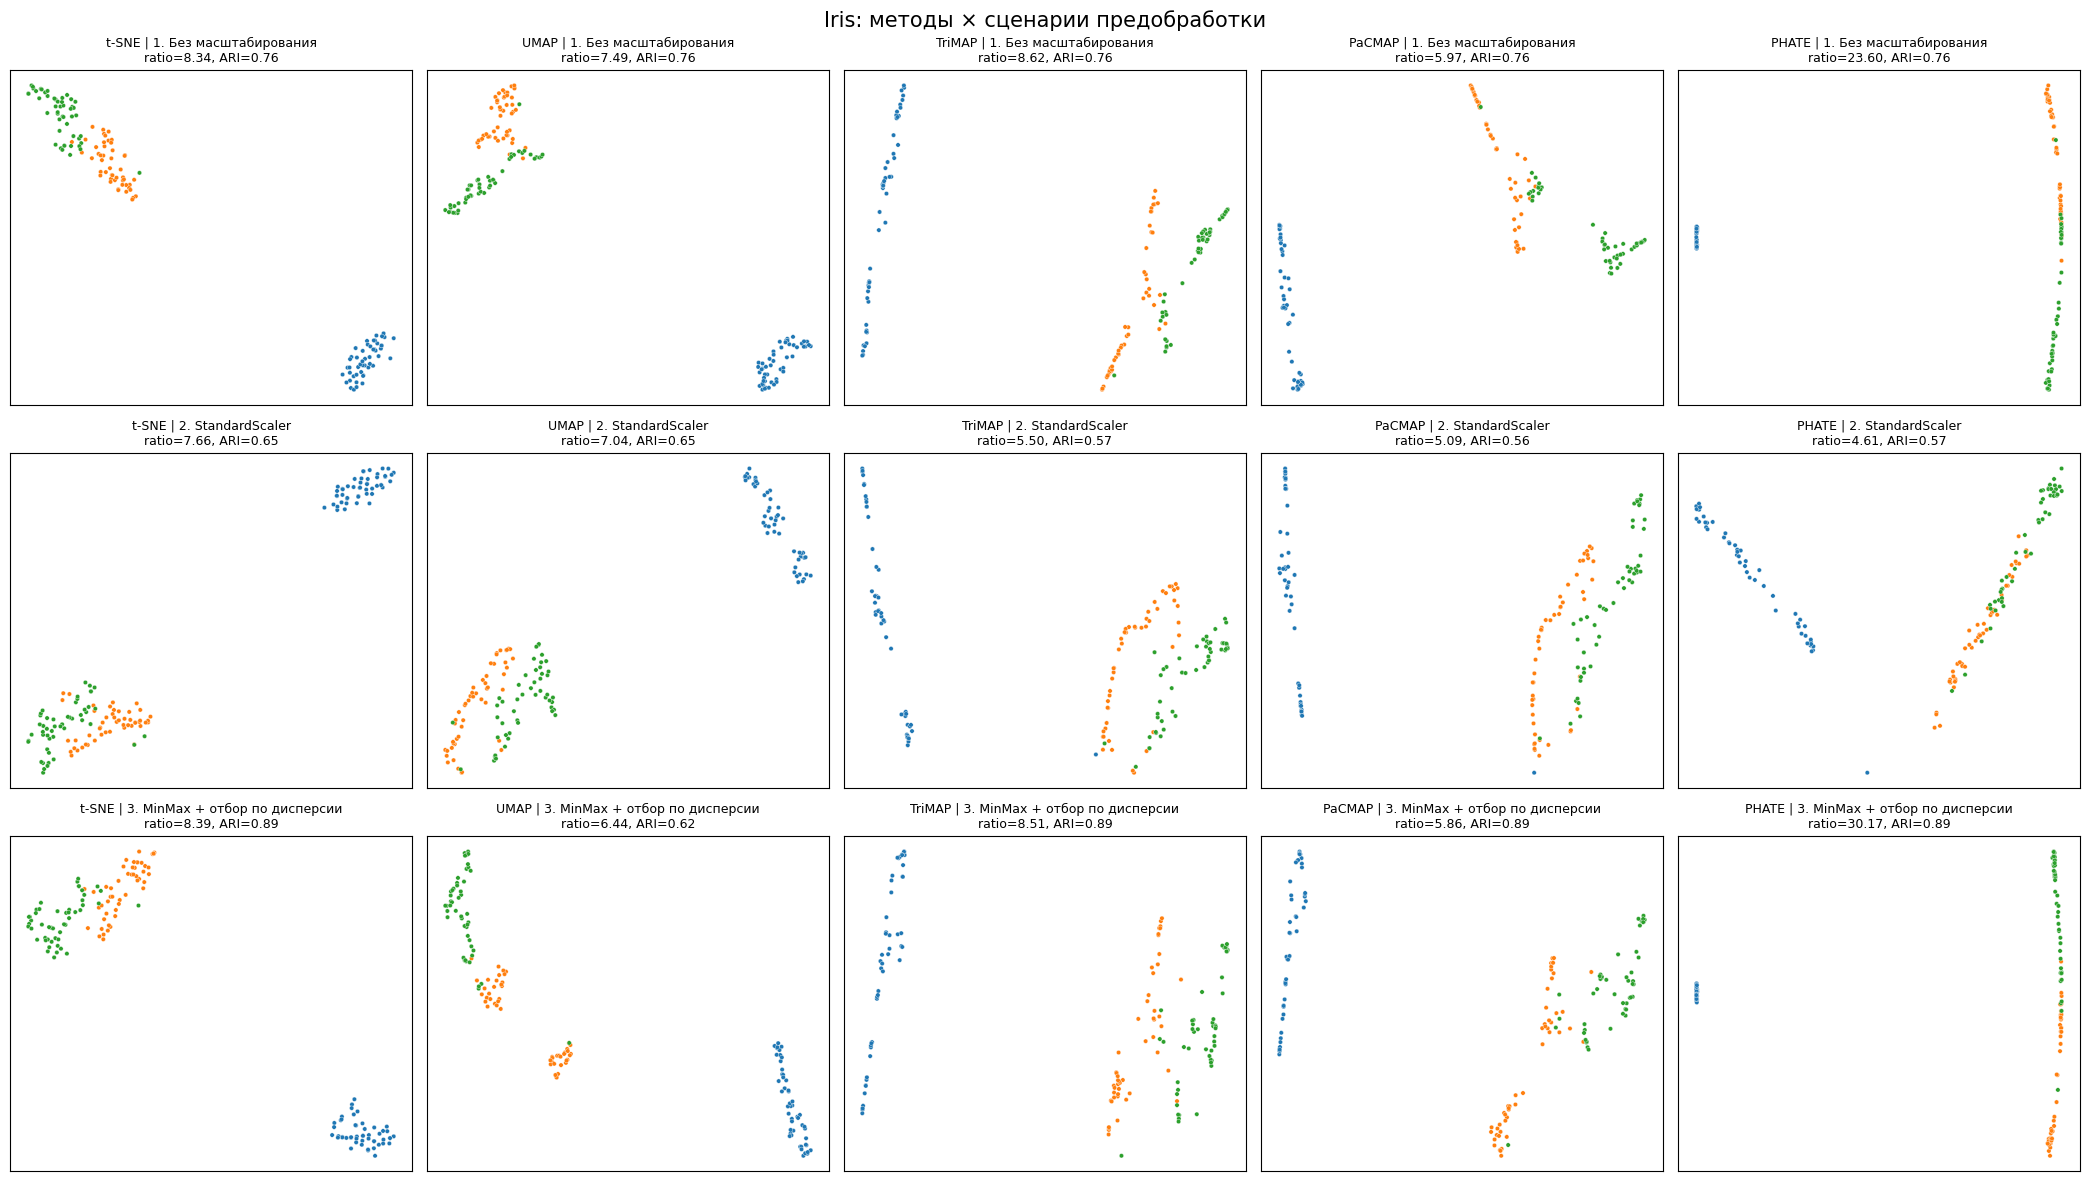

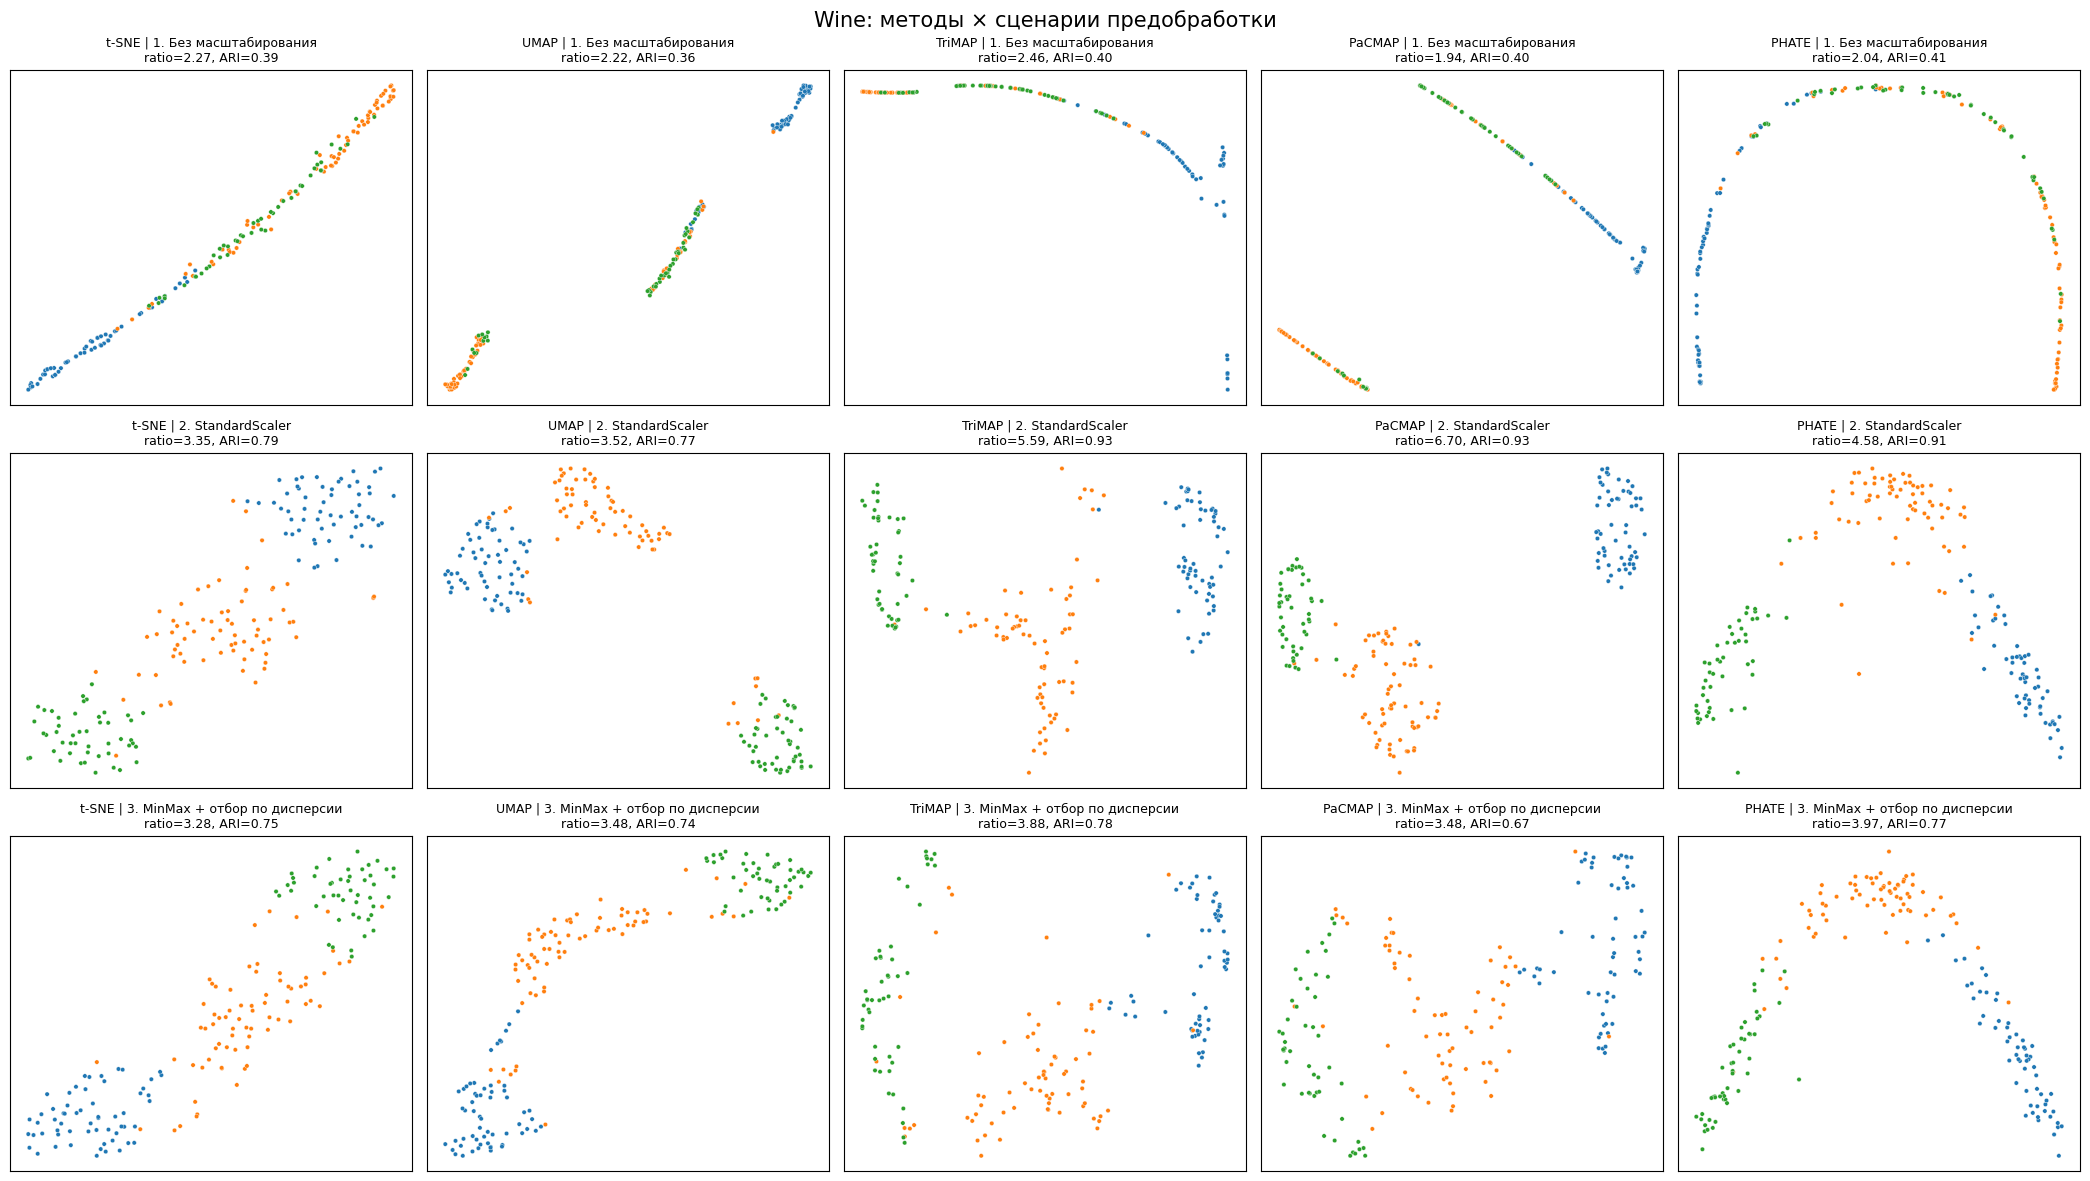

In [19]:
prep_rows, prep_embs = [], {}
for ds, scen in scenarios.items():
    y_ds = datasets[ds][1]
    k = len(np.unique(y_ds))
    for sc_name, Xs in scen.items():
        for m_name, f in METHODS.items():
            t0 = time.perf_counter()
            E = f(Xs)
            dt = time.perf_counter() - t0
            prep_embs[(ds, sc_name, m_name)] = E
            prep_rows.append({
                "Датасет": ds, "Сценарий": sc_name, "Метод": m_name, "Время, с": dt,
                "ratio": separation_score(E, y_ds)[2],
                "ARI KMeans": adjusted_rand_score(y_ds, KMeans(k, n_init=10, random_state=0).fit_predict(E)),
                "ARI Ward": adjusted_rand_score(y_ds, AgglomerativeClustering(k).fit_predict(E)),
            })
prep_df = pd.DataFrame(prep_rows)

for ds in scenarios:
    fig, axes = plt.subplots(3, 5, figsize=(21, 12))
    for i, sc_name in enumerate(scenarios[ds]):
        for j, m_name in enumerate(METHODS):
            E = prep_embs[(ds, sc_name, m_name)]
            r = prep_df[(prep_df["Датасет"] == ds) & (prep_df["Сценарий"] == sc_name) & (prep_df["Метод"] == m_name)].iloc[0]
            sns.scatterplot(x=E[:, 0], y=E[:, 1], hue=datasets[ds][1], palette="tab10", s=10,
                            ax=axes[i, j], legend=False)
            axes[i, j].set_title(f"{m_name} | {sc_name}\nratio={r['ratio']:.2f}, ARI={r['ARI KMeans']:.2f}", fontsize=9)
            axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
    plt.suptitle(f"{ds}: методы × сценарии предобработки", fontsize=15)
    plt.tight_layout(); plt.show()

In [20]:
for metric in ["ARI KMeans", "ARI Ward", "ratio"]:
    print(f"\n===== {metric} =====")
    print(prep_df.pivot_table(index=["Датасет", "Сценарий"], columns="Метод", values=metric).round(3))


===== ARI KMeans =====
Метод                                   PHATE  PaCMAP  TriMAP   UMAP  t-SNE
Датасет Сценарий                                                           
Iris    1. Без масштабирования          0.759   0.759   0.759  0.759  0.759
        2. StandardScaler               0.571   0.562   0.571  0.652  0.652
        3. MinMax + отбор по дисперсии  0.886   0.886   0.886  0.625  0.886
Wine    1. Без масштабирования          0.407   0.401   0.401  0.363  0.391
        2. StandardScaler               0.913   0.933   0.933  0.774  0.788
        3. MinMax + отбор по дисперсии  0.774   0.669   0.778  0.743  0.745

===== ARI Ward =====
Метод                                   PHATE  PaCMAP  TriMAP   UMAP  t-SNE
Датасет Сценарий                                                           
Iris    1. Без масштабирования          0.732   0.759   0.759  0.759  0.759
        2. StandardScaler               0.654   0.581   0.630  0.705  0.705
        3. MinMax + отбор по дисперсии  0.

- Wine без масштабирования: у всех методов кривая по пролину, ARI ≈ 0.4.
- StandardScaler - лучший сценарий (TriMAP/PaCMAP 0.93).
- MinMax + отбор: хуже, PaCMAP 0.67.
- Iris: наоборот, отбор помогает (0.886).

Предобработка важнее выбора метода.

### Время и масштабируемость (make_blobs, n = 500…4000)

Время на Iris/Wine (стандартизованные данные), с:
Датасет  Iris  Wine
Метод              
PHATE    0.09  0.11
PaCMAP   0.24  0.24
TriMAP   0.15  0.15
UMAP     0.15  0.20
t-SNE    0.36  0.46


    SGD-MDS may not have converged: stress changed by 1.7% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by -1.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.


    SGD-MDS may not have converged: stress changed by -1.5% in final iterations. Consider increasing n_iter or adjusting learning_rate.


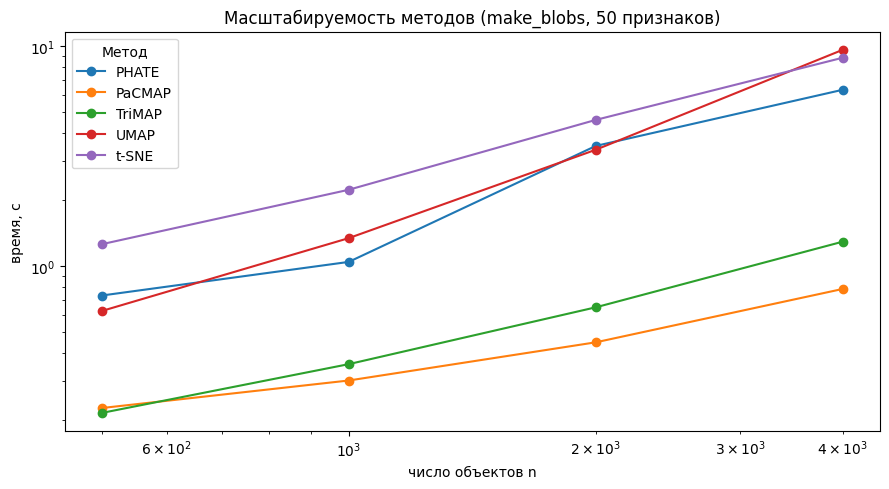

Метод  PHATE  PaCMAP  TriMAP  UMAP  t-SNE
n                                        
500     0.73    0.23    0.21  0.62   1.25
1000    1.04    0.30    0.36  1.34   2.22
2000    3.51    0.45    0.65  3.37   4.60
4000    6.31    0.79    1.29  9.59   8.83

Оценка показателя степени α (t ~ n^α): {'PHATE': np.float64(1.11), 'PaCMAP': np.float64(0.6), 'TriMAP': np.float64(0.86), 'UMAP': np.float64(1.32), 't-SNE': np.float64(0.95)}


In [21]:
print("Время на Iris/Wine (стандартизованные данные), с:")
print(prep_df[prep_df["Сценарий"] == "2. StandardScaler"].pivot(index="Метод", columns="Датасет", values="Время, с").round(2))

sizes = [500, 1000, 2000, 4000]
scal_rows = []
for n in sizes:
    Xb, yb = make_blobs(n_samples=n, n_features=50, centers=10, cluster_std=4.0, random_state=0)
    Xb = StandardScaler().fit_transform(Xb)
    for m_name, f in METHODS.items():
        t0 = time.perf_counter()
        f(Xb)
        scal_rows.append({"n": n, "Метод": m_name, "Время, с": time.perf_counter() - t0})
scal_df = pd.DataFrame(scal_rows).pivot(index="n", columns="Метод", values="Время, с")

ax = scal_df.plot(marker="o", logx=True, logy=True, figsize=(9, 5))
ax.set_xlabel("число объектов n"); ax.set_ylabel("время, с")
ax.set_title("Масштабируемость методов (make_blobs, 50 признаков)")
plt.tight_layout(); plt.show()

slopes = {m: np.polyfit(np.log(sizes), np.log(scal_df[m].values), 1)[0] for m in scal_df.columns}
print(scal_df.round(2))
print("\nОценка показателя степени α (t ~ n^α):", {m: round(a, 2) for m, a in slopes.items()})

n = 4000: PaCMAP 0.8 с, TriMAP 1.3, PHATE 6, t-SNE 9, UMAP 9 (однопоточный из-за seed).
Наклон α: PaCMAP 0.6, TriMAP 0.8, t-SNE 1.0, PHATE 1.1, UMAP 1.3. Для больших данных - PaCMAP, TriMAP, UMAP.

### Гиперпараметры × предобработка (Wine)

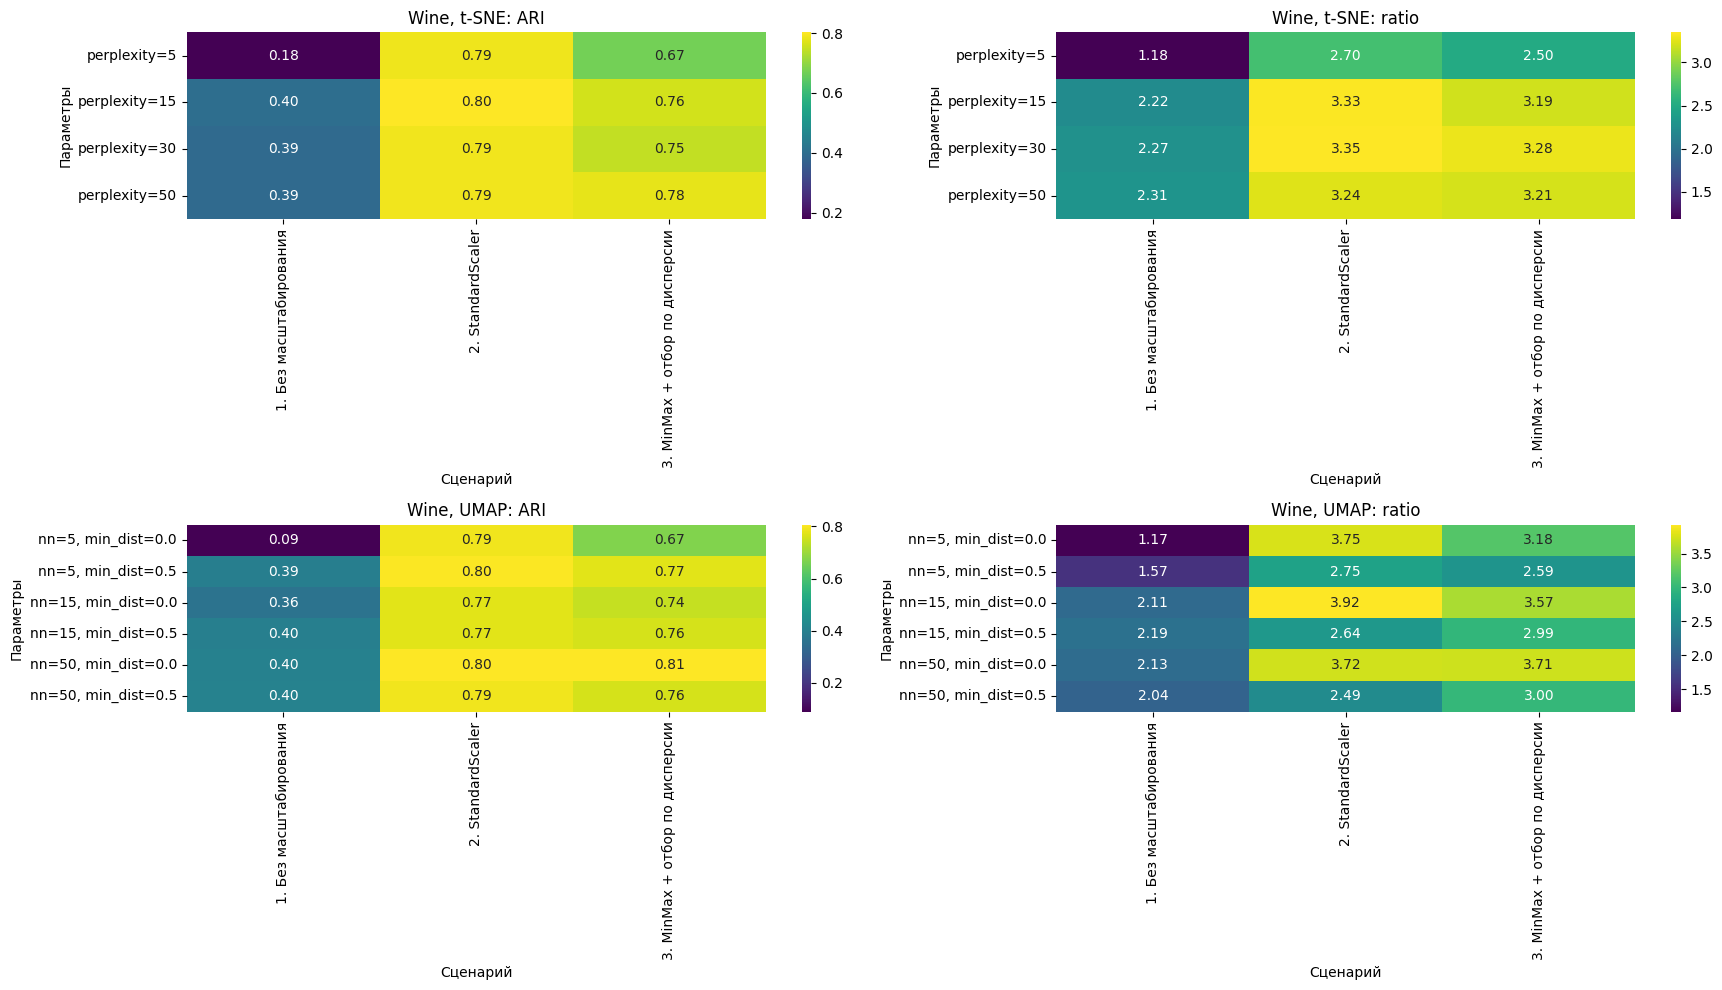

In [22]:
joint_rows = []
y_w = datasets["Wine"][1]
for sc_name, Xs in scenarios["Wine"].items():
    for perp in [5, 15, 30, 50]:
        E = run_tsne(Xs, perplexity=perp)
        joint_rows.append({"Метод": "t-SNE", "Параметры": f"perplexity={perp}", "Сценарий": sc_name,
                           "ratio": separation_score(E, y_w)[2],
                           "ARI": adjusted_rand_score(y_w, KMeans(3, n_init=10, random_state=0).fit_predict(E))})
    for nn in [5, 15, 50]:
        for md_ in [0.0, 0.5]:
            E = run_umap(Xs, n_neighbors=nn, min_dist=md_)
            joint_rows.append({"Метод": "UMAP", "Параметры": f"nn={nn}, min_dist={md_}", "Сценарий": sc_name,
                               "ratio": separation_score(E, y_w)[2],
                               "ARI": adjusted_rand_score(y_w, KMeans(3, n_init=10, random_state=0).fit_predict(E))})
joint_df = pd.DataFrame(joint_rows)

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
for i, m_name in enumerate(["t-SNE", "UMAP"]):
    sub = joint_df[joint_df["Метод"] == m_name]
    for j, metric in enumerate(["ARI", "ratio"]):
        piv = sub.pivot(index="Параметры", columns="Сценарий", values=metric).reindex(sub["Параметры"].unique())
        sns.heatmap(piv, annot=True, fmt=".2f", cmap="viridis", ax=axes[i, j])
        axes[i, j].set_title(f"Wine, {m_name}: {metric}")
plt.tight_layout(); plt.show()

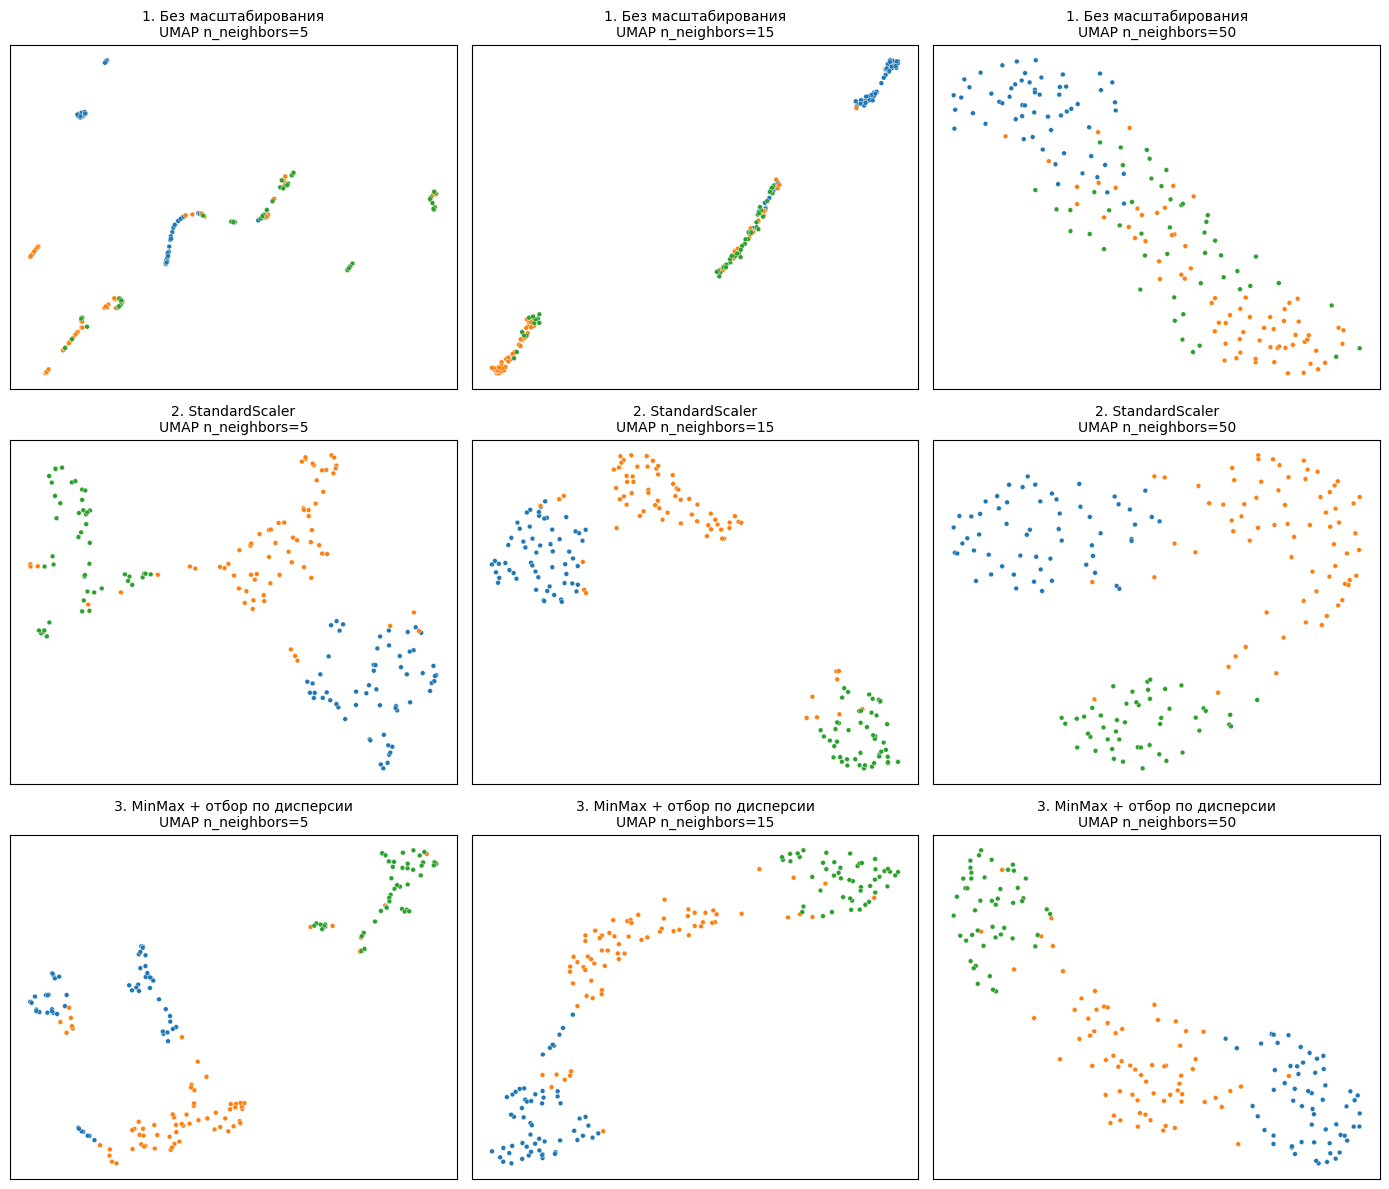

In [23]:
# Визуально: UMAP на Wine - строки = сценарии, столбцы = n_neighbors (min_dist = 0.1)
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for i, (sc_name, Xs) in enumerate(scenarios["Wine"].items()):
    for j, nn in enumerate([5, 15, 50]):
        E = run_umap(Xs, n_neighbors=nn, min_dist=0.1)
        sns.scatterplot(x=E[:, 0], y=E[:, 1], hue=y_w, palette="tab10", s=12, ax=axes[i, j], legend=False)
        axes[i, j].set_title(f"{sc_name}\nUMAP n_neighbors={nn}", fontsize=10)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
plt.tight_layout(); plt.show()

- Без масштабирования ARI ≤ 0.4 при любых параметрах, со StandardScaler 0.77–0.80 почти при любых.
- Маленькие окрестности на плохой метрике всё дробят: perplexity 5 → 0.18.
- min_dist меняет ratio, но не ARI.

## Выводы
- t-SNE лучше держит локальную структуру, TriMAP/PaCMAP/PHATE - глобальную.
- t-SNE самый чувствительный к параметрам, UMAP - к seed.
- Предобработка важнее выбора метода; отбор по дисперсии после MinMax может выкинуть информативные признаки.
- Быстрее всех масштабируются PaCMAP и TriMAP.